In [17]:
## Natural Gas Price Estimator
# Goal: Estimate the purchase price of natural gas for any date (past or future)
# Data: Monthly prices from Oct 2020 to Sep 2024

In [18]:
# 1. Load
import pandas as pd

df = pd.read_csv("Nat_gas.csv")
print(df.head())      # first 5 rows
print(df.tail())      # last 5 rows
print(df.shape)       # how many rows/columns
print(df.dtypes)      # what type is each column

      Dates  Prices
0  10/31/20    10.1
1  11/30/20    10.3
2  12/31/20    11.0
3   1/31/21    10.9
4   2/28/21    10.9
      Dates  Prices
43  5/31/24    11.4
44  6/30/24    11.5
45  7/31/24    11.6
46  8/31/24    11.5
47  9/30/24    11.8
(48, 2)
Dates      object
Prices    float64
dtype: object


In [19]:
# 2. Clean
df["Dates"] = pd.to_datetime(df["Dates"]) #convert object to dates
print(df.dtypes)  # Dates should now say datetime64

Dates     datetime64[ns]
Prices           float64
dtype: object


/var/folders/g0/yvzrb9y11ls5skswtdx2m49h0000gn/T/ipykernel_5259/3035341667.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dates"] = pd.to_datetime(df["Dates"]) #convert object to dates


In [20]:
#empty/null/missing
print(df.isnull().sum())

Dates     0
Prices    0
dtype: int64


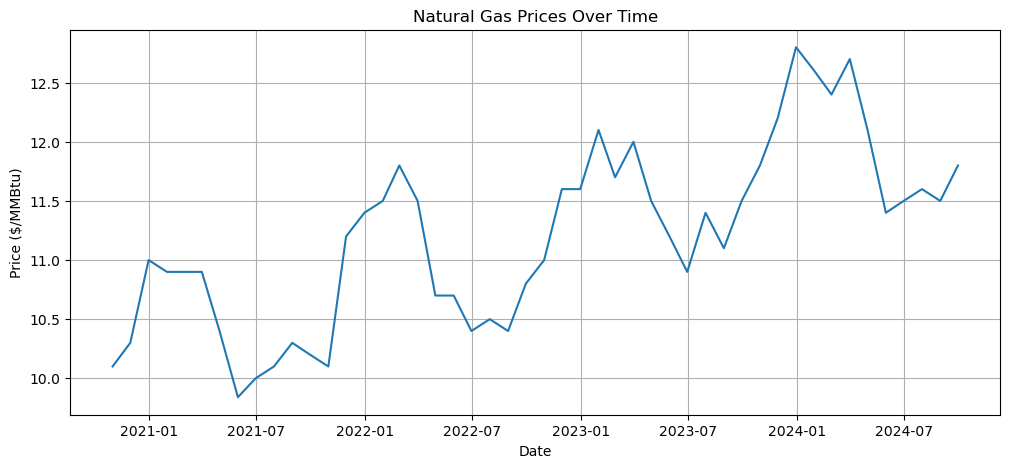

In [21]:
# 3. explore
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df["Dates"], df["Prices"])
plt.title("Natural Gas Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Price ($/MMBtu)") #standard energy million (MM), british thermal unit (Btu) [how much energy it contain]
plt.grid(True)
plt.show()

## Observations (Maybe)
- overall up trend from 10$ to 12$
- seasons has effect on the price
- huge at the end of 2023/begining 2024

In [22]:
## Exploratory Data Analysis
# Observations:
# 1. Clear upward trend from ~$10 (2020) to ~$12 (2024)
# 2. Seasonal pattern: prices peak in winter (Dec-Mar), dip in summer (May-Aug)
# 3. No missing values, 48 data points

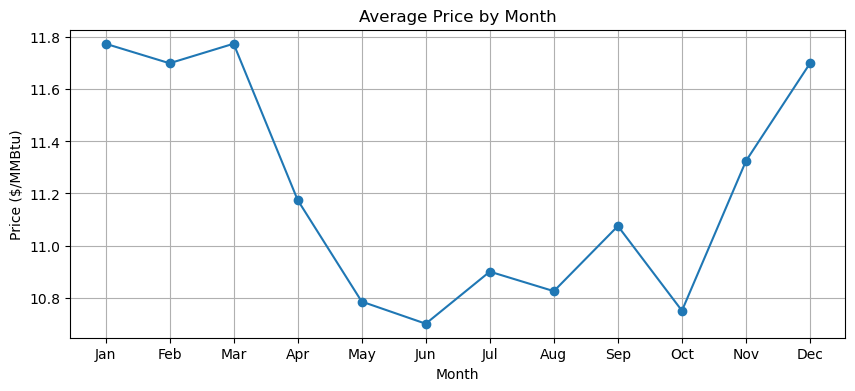

In [23]:

#Seasonality .. check all the months (avg all month over yrs)
df["Month"] = df["Dates"].dt.month
monthly_avg = df.groupby("Month")["Prices"].mean()

plt.figure(figsize=(10, 4))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Average Price by Month")
plt.xlabel("Month")
plt.ylabel("Price ($/MMBtu)")
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.grid(True)
plt.show()

In [24]:
#examine trendline 
#converting to number for regression
df["Days"] = (df["Dates"] - df["Dates"].min()).dt.days
print(df[["Dates", "Days"]].head())
df["Days"] = (df["Dates"] - df["Dates"].min()).dt.days
print(df[["Dates", "Days"]].head())

       Dates  Days
0 2020-10-31     0
1 2020-11-30    30
2 2020-12-31    61
3 2021-01-31    92
4 2021-02-28   120
       Dates  Days
0 2020-10-31     0
1 2020-11-30    30
2 2020-12-31    61
3 2021-01-31    92
4 2021-02-28   120


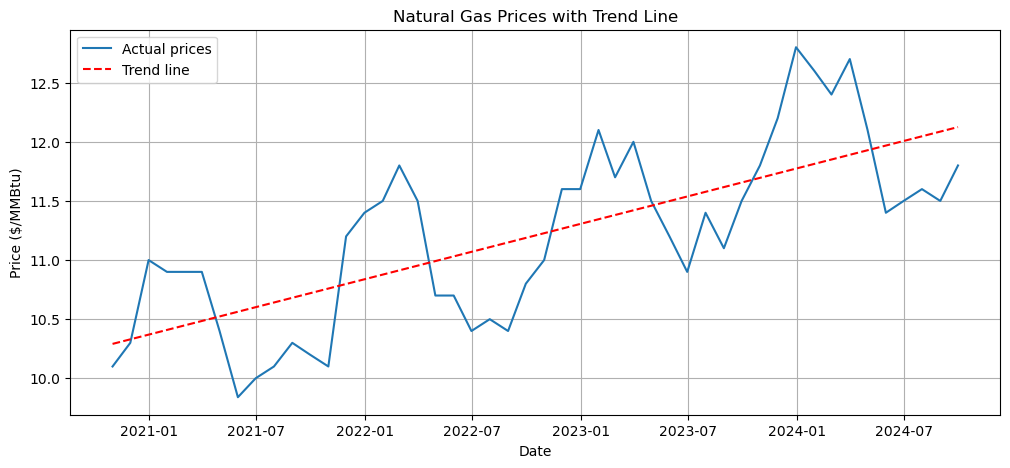

In [25]:
#trendline
import numpy as np

z = np.polyfit(df["Days"], df["Prices"], 1)
p = np.poly1d(z)

plt.figure(figsize=(12, 5))
plt.plot(df["Dates"], df["Prices"], label="Actual prices")
plt.plot(df["Dates"], p(df["Days"]), label="Trend line", 
         linestyle="--", color="red")
plt.title("Natural Gas Prices with Trend Line")
plt.xlabel("Date")
plt.ylabel("Price ($/MMBtu)")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
## Model
# Approach:
# - Interpolation (dates within data range): Cubic Spline
# - Extrapolation (future dates): Linear Trend + Seasonal Correction
# 
# Why this approach:
# - EDA showed two patterns: upward trend + seasonality
# - Spline gives smooth estimates between known points
# - Trend + seasonal correction captures both patterns for future predictions

In [27]:
#Model
# interpolation / Estimation / Past
from scipy.interpolate import CubicSpline

cs = CubicSpline(df["Days"], df["Prices"])

In [28]:
print(cs(0))      # price at day 0 (Oct 31 2020)
print(cs(1430))   # price at day 1430 (Sep 30 2024)
print(cs(500))    # price at day 500 (somewhere in 2022)

10.1
11.799999999999999
11.772086010768284


In [29]:
# model
#extrapolation/future price
#time series decomposition: Price = Trend + Seasonality + Noise
# predicted price = trend value + seasonal correction

#correction_seasonal: residual(how far from trend)
df["Trend"] = p(df["Days"])
df["Residual"] = df["Prices"] - df["Trend"]
print(df[["Dates", "Prices", "Trend", "Residual"]].head(10))

       Dates  Prices      Trend  Residual
0 2020-10-31   10.10  10.291041 -0.191041
1 2020-11-30   10.30  10.329512 -0.029512
2 2020-12-31   11.00  10.369266  0.630734
3 2021-01-31   10.90  10.409019  0.490981
4 2021-02-28   10.90  10.444926  0.455074
5 2021-03-31   10.90  10.484680  0.415320
6 2021-04-30   10.40  10.523151 -0.123151
7 2021-05-31    9.84  10.562904 -0.722904
8 2021-06-30   10.00  10.601376 -0.601376
9 2021-07-31   10.10  10.641129 -0.541129


In [30]:
#avg risiduals
seasonal_correction = df.groupby(df["Dates"].dt.month)["Residual"].mean()
print(seasonal_correction)

Dates
1     0.663881
2     0.552654
3     0.587900
4    -0.050571
5    -0.480324
6    -0.603796
7    -0.443549
8    -0.558303
9    -0.346774
10   -0.243141
11    0.293388
12    0.628635
Name: Residual, dtype: float64


In [31]:
# the date we want to predict
future_date = pd.to_datetime("2025-03-31")

# step 1: convert to day number
day_number = (future_date - df["Dates"].min()).days
print("Day number:", day_number)

# step 2: get the trend value
trend_value = p(day_number)
print("Trend says:", trend_value)

# step 3: get seasonal correction for March (month 3)
correction = seasonal_correction[3]
print("March correction:", correction)

# step 4: combine them
predicted_price = trend_value + correction
print("Predicted price:", predicted_price)

Day number: 1612
Trend says: 12.35822736715376
March correction: 0.5879003219140122
Predicted price: 12.946127689067772


In [32]:
#FUNCTION [Input: date, Output: price]
#If date is INSIDE the data range → use cs (interpolation)
#If date is OUTSIDE the data range → use trend + seasonal (extrapolation)

In [33]:
def estimate_price(date):
    # convert string to datetime
    date = pd.to_datetime(date)
    
    # convert to day number
    day_number = (date - df["Dates"].min()).days
    
    # what's the range of our data?
    min_day = df["Days"].min()   # 0
    max_day = df["Days"].max()   # 1430
    
    # decide which method to use
    if min_day <= day_number <= max_day:
        # inside data range → interpolation
        price = cs(day_number)
    else:
        # outside data range → extrapolation
        trend_value = p(day_number)
        month = date.month
        correction = seasonal_correction[month]
        price = trend_value + correction
    
    return round(float(price), 2)

In [34]:
#TEST
# inside data range (interpolation)
print("Jun 15, 2022:", estimate_price("2022-06-15"))
print("Dec 25, 2021:", estimate_price("2021-12-25"))

# exact data points (should match original)
print("Oct 31, 2020:", estimate_price("2020-10-31"))

# future dates (extrapolation)
print("Mar 31, 2025:", estimate_price("2025-03-31"))
print("Jun 30, 2025:", estimate_price("2025-06-30"))
print("Sep 30, 2025:", estimate_price("2025-09-30"))

Jun 15, 2022: 10.55
Dec 25, 2021: 11.42
Oct 31, 2020: 10.1
Mar 31, 2025: 12.95
Jun 30, 2025: 11.87
Sep 30, 2025: 12.25


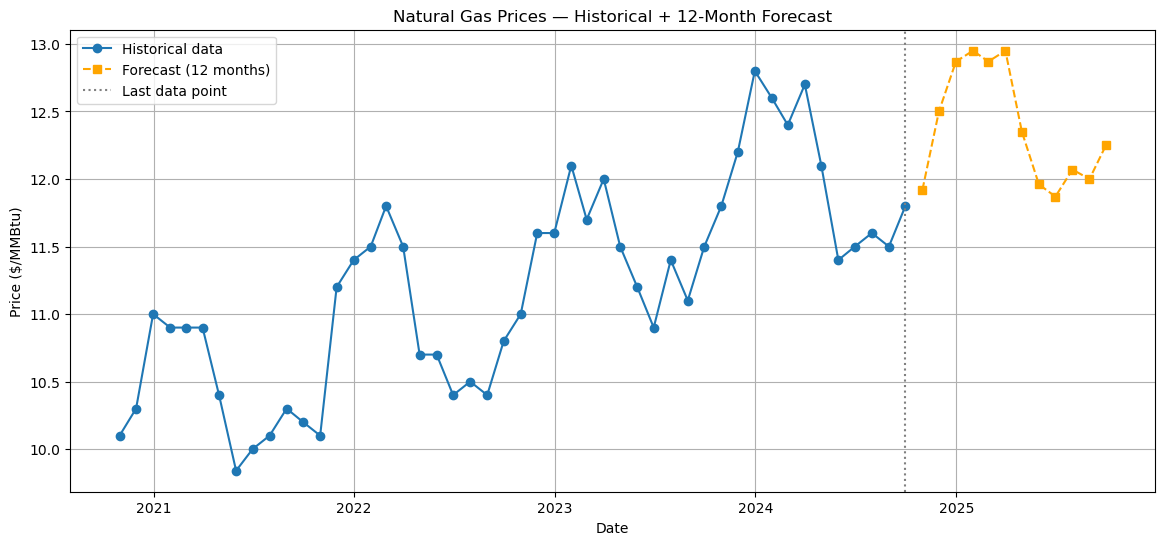

In [35]:
# generate future dates (1 year beyond last data point)
last_date = df["Dates"].max()
future_dates = pd.date_range(last_date + pd.DateOffset(months=1), 
                              periods=12, freq="ME")

# get predicted prices for each future month
future_prices = [estimate_price(date) for date in future_dates]

# plot everything together
plt.figure(figsize=(14, 6))
plt.plot(df["Dates"], df["Prices"], marker="o", label="Historical data")
plt.plot(future_dates, future_prices, marker="s", linestyle="--", 
         color="orange", label="Forecast (12 months)")
plt.axvline(last_date, color="gray", linestyle=":", label="Last data point")
plt.title("Natural Gas Prices — Historical + 12-Month Forecast")
plt.xlabel("Date")
plt.ylabel("Price ($/MMBtu)")
plt.legend()
plt.grid(True)
plt.show()